# Fase 5 CRISP-DM — Evaluación final y análisis de errores

Este cuaderno evalúa los cuatro modelos de calidad entrenados en la fase 4 sobre dos conjuntos que **no se usaron para entrenar ni para elegir hiperparámetros**:

1. **Test Kaggle**: la partición `test` de `experiments/results/prepared_features_dataset.csv` (misma distribución que train/val).
2. **Test real**: las fotos propias del grupo en `data/custom_group_photos/`, tomadas con otras cámaras, fondos e iluminación. Mide el *domain shift*.

Además compara la talla estimada con $d_{norm}$ contra la talla anotada a mano, construye la tabla de sobreajuste (CV agrupada → Val → Test Kaggle → Test real), analiza casos mal clasificados y fija el modelo que se despliega en la fase 6.

| Modelo | Checkpoint | Papel |
|---|---|---|
| Regresión logística | `fase4_regresion_logistica.joblib` | Línea base lineal |
| SVM RBF | `fase4_svm_rbf.joblib` | ML tradicional #1 |
| Random Forest | `fase4_random_forest.joblib` | ML tradicional #2 |
| MLP (96, 48, 24) | `fase4_mlp.joblib` | Red neuronal sobre las 31 características |

In [1]:
import json
import math
import re
import tempfile
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from IPython.display import display
from PIL import Image
from scipy import ndimage
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)

warnings.filterwarnings('ignore', category=UserWarning)
plt.rcParams.update({'font.family': 'sans-serif', 'font.size': 10, 'axes.titlesize': 11,
                     'axes.titleweight': 'bold', 'figure.dpi': 110})

DATA_FILE = Path('experiments/results/prepared_features_dataset.csv')
ROOT = next(f for f in (Path.cwd(), *Path.cwd().parents) if (f / DATA_FILE).is_file())
RESULTS_DIR = ROOT / 'experiments' / 'results'
CHECKPOINTS_DIR = ROOT / 'experiments' / 'checkpoints'
FIG_DIR = RESULTS_DIR / 'eval_figures'
CUSTOM_DIR = ROOT / 'data' / 'custom_group_photos'
FIG_DIR.mkdir(parents=True, exist_ok=True)

fase4 = json.loads((RESULTS_DIR / 'fase4_modelado_metricas.json').read_text(encoding='utf-8'))
FEATURES = fase4['feature_names']
CLASSES = fase4['class_order']                      # ['Bad', 'Good', 'Mixed']
CATALOG_FRUITS = ['Apple', 'Banana', 'Guava', 'Lime', 'Orange', 'Pomegranate']
SIZE_ORDER = ['Small', 'Medium', 'Large']
SIZE_THRESHOLDS = json.loads((RESULTS_DIR / 'size_thresholds_train.json').read_text(encoding='utf-8'))
TARGET_SIZE = (128, 128)
QUALITY_PALETTE = {'Good': '#2ca02c', 'Mixed': '#ff7f0e', 'Bad': '#d62728'}

MODEL_NAMES = {
    'regresion_logistica': 'Regresión logística',
    'svm_rbf': 'SVM RBF',
    'random_forest': 'Random Forest',
    'mlp': 'MLP',
}
models = {key: joblib.load(CHECKPOINTS_DIR / f'fase4_{key}.joblib') for key in MODEL_NAMES}
for key, model in models.items():
    assert list(model.feature_names_in_) == FEATURES, key
    assert list(model.classes_) == CLASSES, key

def save_figure(fig, name):
    fig.savefig(FIG_DIR / f'{name}.pdf', bbox_inches='tight', metadata={'CreationDate': None})  # PDF reproducible
    fig.savefig(FIG_DIR / f'{name}.png', dpi=200, bbox_inches='tight')

print(f'scikit-learn {sklearn.__version__} (checkpoints guardados con {fase4["sklearn_version"]})')
print(f'{len(models)} modelos cargados; {len(FEATURES)} características; clases {CLASSES}')

scikit-learn 1.7.2 (checkpoints guardados con 1.7.2)
4 modelos cargados; 31 características; clases ['Bad', 'Good', 'Mixed']


## 1. Extractor de características $\phi(I)$ de la fase 3

Las funciones siguientes son **copia literal** de las celdas 5 y 12 de `02_Preparacion_Datos_y_Extraccion_Caracteristicas.ipynb` (`otsu_threshold`, `rgb_to_hsv_array`, `extract_individual_crops_from_mixed`, `segment_foreground_fast` y `extract_full_feature_vector`). Se copian sin cambios para que las fotos propias se describan exactamente con las mismas 31 características que vieron los modelos.

In [2]:
def otsu_threshold(gray_values: np.ndarray) -> float:
    hist, bin_edges = np.histogram(gray_values.ravel(), bins=256, range=(0.0, 1.0))
    hist = hist.astype(np.float64)
    total = hist.sum()
    if total == 0:
        return 0.5
    prob = hist / total
    bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
    w0 = np.cumsum(prob)
    w1 = 1.0 - w0
    mu = np.cumsum(prob * bin_centers)
    valid = (w0 > 1e-6) & (w1 > 1e-6)
    sigma_b_sq = np.zeros_like(w0)
    sigma_b_sq[valid] = ((mu[-1] * w0[valid] - mu[valid]) ** 2) / (w0[valid] * w1[valid])
    return float(bin_centers[int(np.argmax(sigma_b_sq))])


def rgb_to_hsv_array(rgb_norm: np.ndarray) -> np.ndarray:
    r, g, b = rgb_norm[..., 0], rgb_norm[..., 1], rgb_norm[..., 2]
    maxc = np.maximum(np.maximum(r, g), b)
    minc = np.minimum(np.minimum(r, g), b)
    v = maxc
    deltac = maxc - minc
    s = np.where(maxc > 1e-6, deltac / np.maximum(maxc, 1e-6), 0.0)
    h = np.zeros_like(maxc)
    mask = deltac > 1e-6
    rc = np.where(mask, (maxc - r) / np.maximum(deltac, 1e-6), 0.0)
    gc = np.where(mask, (maxc - g) / np.maximum(deltac, 1e-6), 0.0)
    bc = np.where(mask, (maxc - b) / np.maximum(deltac, 1e-6), 0.0)
    cond_r = mask & (r == maxc)
    cond_g = mask & (g == maxc) & ~cond_r
    cond_b = mask & ~cond_r & ~cond_g
    h[cond_r] = bc[cond_r] - gc[cond_r]
    h[cond_g] = 2.0 + rc[cond_g] - bc[cond_g]
    h[cond_b] = 4.0 + gc[cond_b] - rc[cond_b]
    h = (h / 6.0) % 1.0
    return np.stack([h, s, v], axis=-1)

In [3]:
def extract_individual_crops_from_mixed(image_path: str, max_crops: int = 6) -> list:
    """Detecta y recorta ejemplares individuales presentes en una foto de Mixed Qualit_Fruits."""
    with Image.open(image_path) as img:
        img_rgb = img.convert('RGB')
        w, h = img_rgb.size
        rgb_arr = np.asarray(img_rgb, dtype=np.float32) / 255.0

    hsv = rgb_to_hsv_array(rgb_arr)
    border_px = max(3, min(h, w) // 20)
    border_samples = np.concatenate([
        rgb_arr[:border_px, :, :].reshape(-1, 3),
        rgb_arr[-border_px:, :, :].reshape(-1, 3),
        rgb_arr[:, :border_px, :].reshape(-1, 3),
        rgb_arr[:, -border_px:, :].reshape(-1, 3),
    ], axis=0)
    bg_rgb = np.median(border_samples, axis=0)
    color_dist = np.linalg.norm(rgb_arr - bg_rgb[None, None, :], axis=-1) / math.sqrt(3.0)

    # Saliencia combinando contraste con fondo y saturación cromática
    salience = np.clip(0.55 * color_dist + 0.45 * hsv[..., 1], 0.0, 1.0)
    thresh = otsu_threshold(salience)
    mask = salience > max(thresh, 0.18)
    mask = ndimage.binary_opening(mask, structure=np.ones((5, 5)))
    mask = ndimage.binary_fill_holes(mask)

    labeled, num_features = ndimage.label(mask)
    img_area = float(h * w)
    crops = []
    slices = ndimage.find_objects(labeled)

    for idx, slc in enumerate(slices, start=1):
        if slc is None:
            continue
        comp_area = float((labeled[slc] == idx).sum())
        area_frac = comp_area / img_area
        if not (0.018 <= area_frac <= 0.65):
            continue
        y0, y1 = slc[0].start, slc[0].stop
        x0, x1 = slc[1].start, slc[1].stop
        bh, bw = y1 - y0, x1 - x0
        if min(bh, bw) < 24:
            continue
        # Margen del 12% alrededor de la fruta
        pad_y, pad_x = int(0.12 * bh), int(0.12 * bw)
        cy0, cy1 = max(0, y0 - pad_y), min(h, y1 + pad_y)
        cx0, cx1 = max(0, x0 - pad_x), min(w, x1 + pad_x)
        crop_img = img_rgb.crop((cx0, cy0, cx1, cy1))
        crops.append({'bbox': (cx0, cy0, cx1, cy1), 'image': crop_img})
        if len(crops) >= max_crops:
            break

    # Si no se detectaron múltiples objetos separados, usar recorte central de la imagen
    if len(crops) == 0:
        crops.append({'bbox': (0, 0, w, h), 'image': img_rgb})
    return crops

In [4]:
def segment_foreground_fast(rgb_norm: np.ndarray) -> np.ndarray:
    h, w, _ = rgb_norm.shape
    hsv = rgb_to_hsv_array(rgb_norm)
    b_px = max(2, min(h, w) // 25)
    border = np.concatenate([
        rgb_norm[:b_px, :, :].reshape(-1, 3),
        rgb_norm[-b_px:, :, :].reshape(-1, 3),
        rgb_norm[:, :b_px, :].reshape(-1, 3),
        rgb_norm[:, -b_px:, :].reshape(-1, 3),
    ], axis=0)
    bg_rgb = np.median(border, axis=0)
    color_dist = np.linalg.norm(rgb_norm - bg_rgb[None, None, :], axis=-1) / math.sqrt(3.0)
    salience = np.clip(0.70 * color_dist + 0.30 * hsv[..., 1], 0.0, 1.0)
    thresh = otsu_threshold(salience)
    mask = salience > max(thresh, 0.12)
    mask = ndimage.binary_closing(mask, structure=np.ones((3, 3)))
    mask = ndimage.binary_fill_holes(mask)
    labeled, num_feat = ndimage.label(mask)
    if num_feat > 1:
        sizes = ndimage.sum(mask, labeled, range(1, num_feat + 1))
        mask = labeled == (int(np.argmax(sizes)) + 1)
    if mask.sum() < 0.02 * (h * w):
        yy, xx = np.ogrid[:h, :w]
        mask = ((yy - h / 2.0) ** 2 + (xx - w / 2.0) ** 2) <= (min(h, w) * 0.35) ** 2
    return mask, hsv


def extract_full_feature_vector(image_path: str) -> dict:
    with Image.open(image_path) as img:
        img_resized = img.convert('RGB').resize(TARGET_SIZE, Image.Resampling.BILINEAR)
        rgb_arr = np.asarray(img_resized, dtype=np.float32) / 255.0

    h, w, _ = rgb_arr.shape
    mask, hsv_arr = segment_foreground_fast(rgb_arr)
    total_px = float(h * w)
    fruit_px = float(mask.sum())
    area_ratio = fruit_px / total_px
    d_norm = math.sqrt((4.0 * fruit_px) / (math.pi * total_px))

    ys, xs = np.where(mask)
    bbox_h = float(ys.max() - ys.min() + 1) / float(h)
    bbox_w = float(xs.max() - xs.min() + 1) / float(w)
    bbox_aspect = bbox_w / max(bbox_h, 1e-6)

    fg_rgb = rgb_arr[mask]
    fg_hsv = hsv_arr[mask]

    # Histograma normalizado de Matiz H (8 bins en [0, 1])
    h_hist, _ = np.histogram(fg_hsv[:, 0], bins=8, range=(0.0, 1.0), density=False)
    h_hist = h_hist.astype(np.float32) / max(float(h_hist.sum()), 1.0)

    # Textura: Laplaciano y gradiente de Sobel en luminancia
    gray = 0.299 * rgb_arr[..., 0] + 0.587 * rgb_arr[..., 1] + 0.114 * rgb_arr[..., 2]
    lap = ndimage.laplace(gray)[mask]
    gx = ndimage.sobel(gray, axis=1)
    gy = ndimage.sobel(gray, axis=0)
    grad_mag = np.hypot(gx, gy)[mask]

    # Proporción de píxeles necróticos / oscuros
    dark_ratio = float((fg_hsv[:, 2] < 0.25).mean())
    necrotic_ratio = float(((fg_hsv[:, 2] < 0.35) & (fg_hsv[:, 1] < 0.40)).mean())

    feats = {
        'area_ratio': round(area_ratio, 5),
        'd_norm': round(d_norm, 5),
        'bbox_width_norm': round(bbox_w, 5),
        'bbox_height_norm': round(bbox_h, 5),
        'bbox_aspect_ratio': round(bbox_aspect, 5),
        'mean_R': round(float(fg_rgb[:, 0].mean()), 5),
        'mean_G': round(float(fg_rgb[:, 1].mean()), 5),
        'mean_B': round(float(fg_rgb[:, 2].mean()), 5),
        'std_R': round(float(fg_rgb[:, 0].std()), 5),
        'std_G': round(float(fg_rgb[:, 1].std()), 5),
        'std_B': round(float(fg_rgb[:, 2].std()), 5),
        'mean_H': round(float(fg_hsv[:, 0].mean()), 5),
        'mean_S': round(float(fg_hsv[:, 1].mean()), 5),
        'mean_V': round(float(fg_hsv[:, 2].mean()), 5),
        'std_H': round(float(fg_hsv[:, 0].std()), 5),
        'std_S': round(float(fg_hsv[:, 1].std()), 5),
        'std_V': round(float(fg_hsv[:, 2].std()), 5),
        'laplacian_var': round(float(np.var(lap)), 6),
        'laplacian_abs_mean': round(float(np.abs(lap).mean()), 6),
        'sobel_mean': round(float(grad_mag.mean()), 6),
        'sobel_std': round(float(grad_mag.std()), 6),
        'dark_pixel_ratio': round(dark_ratio, 5),
        'necrotic_pixel_ratio': round(necrotic_ratio, 5),
    }
    for b_idx in range(8):
        feats[f'hue_bin_{b_idx}'] = round(float(h_hist[b_idx]), 5)
    return feats

### 1.1 Verificación de reproducibilidad del extractor

Antes de usarlo sobre fotos nuevas, se recalculan las características de una muestra estratificada del test de Kaggle a partir de las imágenes originales (descargadas con `kagglehub`) y se comparan con las guardadas en la fase 3. Las imágenes son idénticas byte a byte, pero pequeñas diferencias de versión en Pillow/libjpeg cambian algunos píxeles del borde de la máscara; lo relevante es si **cambian las predicciones**.

In [5]:
try:
    import kagglehub
    KAGGLE_DIR = Path(kagglehub.dataset_download('ryandpark/fruit-quality-classification'))
except Exception as exc:  # sin red ni caché: se omiten las secciones que necesitan imágenes de Kaggle
    KAGGLE_DIR = None
    print(f'Dataset de Kaggle no disponible ({exc}); se omiten verificación y casos visuales de Kaggle.')

df_all = pd.read_csv(ROOT / DATA_FILE)
inventory = pd.read_csv(RESULTS_DIR / 'dataset_inventory.csv')
inv_mixed = inventory[inventory['quality'] == 'Mixed'].assign(
    stem=lambda f: f['filename'].str.rsplit('.', n=1).str[0])
BACKSLASH = chr(92)


def kaggle_source(win_path: str) -> Path:
    rel = win_path.split('Proyecto_Final_APO3' + BACKSLASH, 1)[1]
    return KAGGLE_DIR / Path(*rel.split(BACKSLASH))


def kaggle_image_path(row, workdir: Path) -> Path:
    # Good/Bad: imagen original. Mixed: se rehace el recorte de la fase 3 y se guarda igual (JPEG q=92).
    # Devuelve None si el recorte ya no se puede reproducir (la segmentación detectó otro número de frutas).
    if row['quality'] != 'Mixed':
        return kaggle_source(row['filepath'])
    stem, k = re.match(r'(.+)_crop_(\d+)\.jpg$', row['filename']).groups()
    src = inv_mixed[(inv_mixed['stem'] == stem) & (inv_mixed['fruit'] == row['fruit'])].iloc[0]
    crops = extract_individual_crops_from_mixed(str(kaggle_source(src['filepath'])), max_crops=5)
    if int(k) >= len(crops):
        return None
    out = workdir / row['filename']
    crops[int(k)]['image'].save(out, quality=92)
    return out


test_kaggle = df_all[df_all['split'] == 'test'].reset_index(drop=True)
reproducibility = None
if KAGGLE_DIR is not None:
    sample = test_kaggle.groupby('quality').sample(n=100, random_state=0)
    with tempfile.TemporaryDirectory() as tmp:
        paths = {i: kaggle_image_path(r, Path(tmp)) for i, r in sample.iterrows()}
        not_reproducible = [i for i, p in paths.items() if p is None]
        sample = sample.drop(index=not_reproducible)
        recomputed = pd.DataFrame([extract_full_feature_vector(str(paths[i])) for i in sample.index],
                                  index=sample.index)[FEATURES]
    abs_diff = (recomputed - sample[FEATURES]).abs()
    scaled_diff = abs_diff / df_all.loc[df_all['split'] == 'train', FEATURES].std()
    agreement = {MODEL_NAMES[k]: float((m.predict(recomputed) == m.predict(sample[FEATURES])).mean())
                 for k, m in models.items()}
    reproducibility = {
        'n_imagenes': len(sample),
        'recortes_mixed_no_reproducibles': len(not_reproducible),
        'mediana_diferencia_en_desviaciones': float(scaled_diff.stack().median()),
        'p95_diferencia_en_desviaciones': float(scaled_diff.stack().quantile(0.95)),
        'acuerdo_de_prediccion': agreement,
    }
    print(f"{len(sample)} imágenes de test recalculadas. Diferencia típica: "
          f"{reproducibility['mediana_diferencia_en_desviaciones']:.4f} desviaciones estándar "
          f"(p95 = {reproducibility['p95_diferencia_en_desviaciones']:.3f}). "
          f"Recortes Mixed que ya no se reproducen: {len(not_reproducible)}.")
    display(pd.Series(agreement, name='Acuerdo de predicción CSV vs. recálculo').to_frame().style.format('{:.1%}'))

297 imágenes de test recalculadas. Diferencia típica: 0.0068 desviaciones estándar (p95 = 0.237). Recortes Mixed que ya no se reproducen: 3.


,Acuerdo de predicción CSV vs. recálculo
Regresión logística,98.7%
SVM RBF,99.0%
Random Forest,98.7%
MLP,98.7%


## 2. Evaluación 1 — Test Kaggle

2.352 recortes (1.012 `Bad`, 1.021 `Good`, 319 `Mixed`) que no participaron en la búsqueda de hiperparámetros ni en la selección de la fase 4.

,Accuracy,Precision (macro),Recall (macro),F1-macro
Regresión logística,0.8661,0.8409,0.8739,0.8545
SVM RBF,0.9549,0.9454,0.9531,0.9491
Random Forest,0.9600,0.9604,0.9534,0.9568
MLP,0.9758,0.9740,0.9691,0.9715


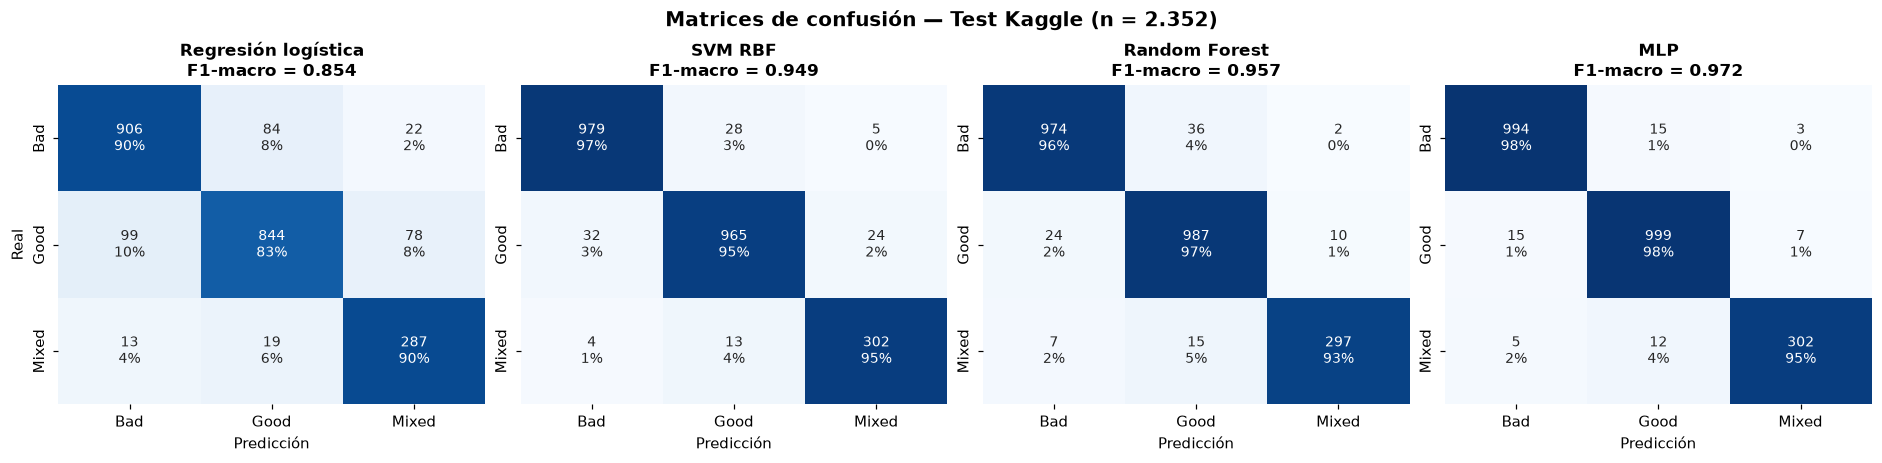

In [6]:
def evaluate(model, X, y):
    pred = model.predict(X)
    return pred, {
        'n': int(len(y)),
        'accuracy': float(accuracy_score(y, pred)),
        'precision_macro': float(precision_score(y, pred, labels=CLASSES, average='macro', zero_division=0)),
        'recall_macro': float(recall_score(y, pred, labels=CLASSES, average='macro', zero_division=0)),
        'f1_macro': float(f1_score(y, pred, labels=CLASSES, average='macro', zero_division=0)),
        'report': classification_report(y, pred, labels=CLASSES, zero_division=0, output_dict=True),
        'confusion_matrix': confusion_matrix(y, pred, labels=CLASSES).tolist(),
    }


def metrics_table(results):
    return pd.DataFrame({MODEL_NAMES[k]: {
        'Accuracy': r['accuracy'], 'Precision (macro)': r['precision_macro'],
        'Recall (macro)': r['recall_macro'], 'F1-macro': r['f1_macro']} for k, r in results.items()}).T


def plot_confusions(results, title, name):
    fig, axes = plt.subplots(1, 4, figsize=(17, 4.1), layout='constrained')
    for ax, (key, res) in zip(axes, results.items()):
        cm = np.array(res['confusion_matrix'])
        norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
        labels = np.array([[f'{c}\n{p:.0%}' for c, p in zip(rc, rp)] for rc, rp in zip(cm, norm)])
        sns.heatmap(norm, annot=labels, fmt='', cmap='Blues', vmin=0, vmax=1, cbar=False,
                    xticklabels=CLASSES, yticklabels=CLASSES, ax=ax, annot_kws={'fontsize': 9})
        ax.set_title(f"{MODEL_NAMES[key]}\nF1-macro = {res['f1_macro']:.3f}")
        ax.set_xlabel('Predicción')
        ax.set_ylabel('Real' if ax is axes[0] else '')
    fig.suptitle(title, fontsize=13, fontweight='bold')
    save_figure(fig, name)
    plt.show()


X_test, y_test = test_kaggle[FEATURES], test_kaggle['quality']
test_results, test_preds = {}, {}
for key, model in models.items():
    test_preds[key], test_results[key] = evaluate(model, X_test, y_test)

display(metrics_table(test_results).style.format('{:.4f}').highlight_max(axis=0, color='#d4edda'))
plot_confusions(test_results, 'Matrices de confusión — Test Kaggle (n = 2.352)', '01_confusion_test_kaggle')

## 3. Evaluación 2 — Test real con fotos propias (*domain shift*)

Las fotos de `data/custom_group_photos/` se normalizaron con `src/data/prepare_custom_photos.py` (orientación EXIF corregida, metadatos eliminados, lado mayor ≤ 512 px; las variantes aumentadas solo se conservan cuando no existe la foto original). La etiqueta `Medium` del protocolo se mapea a la clase `Mixed` de los modelos, igual que en la celda 9 del cuaderno 02.

Para descartar que la normalización altere los resultados, se compararon las predicciones de la MLP con las fotos originales y con las normalizadas en una muestra de 60 fotos: coinciden en el 97 %.

La **granadilla** no pertenece a las seis frutas del dataset de referencia: se reporta aparte y no entra en las métricas principales.

In [7]:
annotations = pd.read_csv(CUSTOM_DIR / 'annotations_template.csv', dtype=str).fillna('')
annotations = annotations[~annotations['filename'].str.startswith('sample_')]
annotations['quality'] = annotations['quality_label'].str.strip().str.lower().map(
    {'good': 'Good', 'medium': 'Mixed', 'mixed': 'Mixed', 'regular': 'Mixed', 'bad': 'Bad'})
annotations['fruit'] = annotations['fruit_type'].str.strip().str.capitalize()
annotations['size_label'] = annotations['size_label'].str.strip().str.capitalize()
annotations['augmented'] = annotations['notes'].str.contains('variante aumentada')
annotations['size_sample'] = annotations['size_sample'].eq('1') if 'size_sample' in annotations else False
assert annotations['quality'].notna().all(), 'Hay etiquetas de calidad no reconocidas'

custom = pd.concat([annotations.reset_index(drop=True), pd.DataFrame(
    [extract_full_feature_vector(str(CUSTOM_DIR / f)) for f in annotations['filename']])], axis=1)
in_catalog = custom['fruit'].isin(CATALOG_FRUITS)
real = custom[in_catalog].reset_index(drop=True)
out_of_catalog = custom[~in_catalog].reset_index(drop=True)

print(f'Fotos propias: {len(custom)} | en catálogo: {len(real)} | fuera de catálogo (granadilla): {len(out_of_catalog)}')
display(pd.crosstab(real['fruit'], real['quality'], margins=True, margins_name='Total'))

Fotos propias: 742 | en catálogo: 724 | fuera de catálogo (granadilla): 18


quality,Bad,Good,Mixed,Total
fruit,,,,
Apple,30,169,24,223
Banana,40,46,66,152
Guava,24,31,62,117
Lime,7,70,5,82
Orange,30,85,35,150
Total,131,401,192,724


,Accuracy,Precision (macro),Recall (macro),F1-macro
Regresión logística,0.5152,0.3021,0.3991,0.3439
SVM RBF,0.4655,0.3205,0.3541,0.3166
Random Forest,0.5028,0.2792,0.3660,0.3160
MLP,0.5028,0.3529,0.3594,0.3214


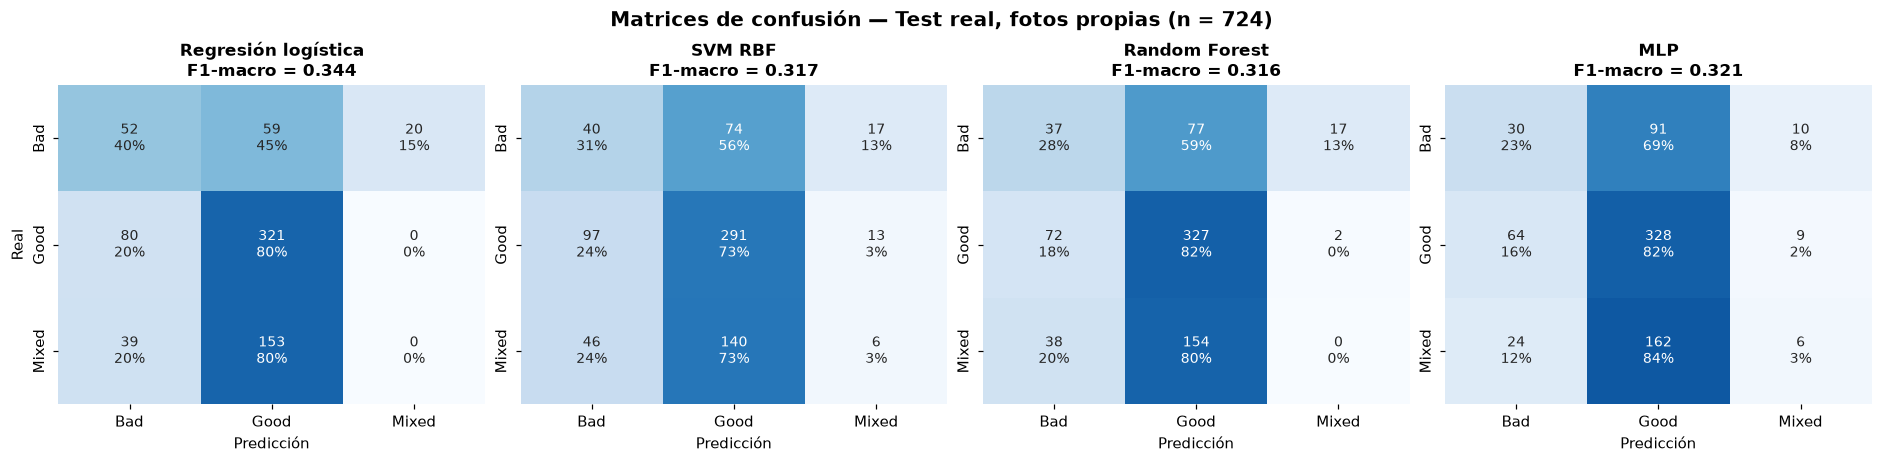

Granadilla (fuera de catálogo), exactitud por modelo: {'Regresión logística': 0.389, 'SVM RBF': 0.333, 'Random Forest': 0.111, 'MLP': 0.333}


In [8]:
real_results, real_preds, real_proba = {}, {}, {}
for key, model in models.items():
    real_preds[key], real_results[key] = evaluate(model, real[FEATURES], real['quality'])
    # La SVM se entrenó sin probability=True: no expone predict_proba (sí lo hacen RF y MLP).
    real_proba[key] = model.predict_proba(real[FEATURES]) if hasattr(model, 'predict_proba') else None

display(metrics_table(real_results).style.format('{:.4f}').highlight_max(axis=0, color='#d4edda'))
plot_confusions(real_results, f'Matrices de confusión — Test real, fotos propias (n = {len(real)})',
                '02_confusion_test_real')

granadilla = {}
if len(out_of_catalog):
    for key, model in models.items():
        granadilla[key] = {'n': int(len(out_of_catalog)), 'accuracy': float(accuracy_score(
            out_of_catalog['quality'], model.predict(out_of_catalog[FEATURES])))}
    print('Granadilla (fuera de catálogo), exactitud por modelo:',
          {MODEL_NAMES[k]: round(v['accuracy'], 3) for k, v in granadilla.items()})

### 3.1 ¿Dónde se desplaza la distribución?

Se comparan las distribuciones de algunas características entre el test de Kaggle y las fotos propias. Si los valores de las fotos reales caen fuera del rango visto en entrenamiento, los modelos extrapolan.

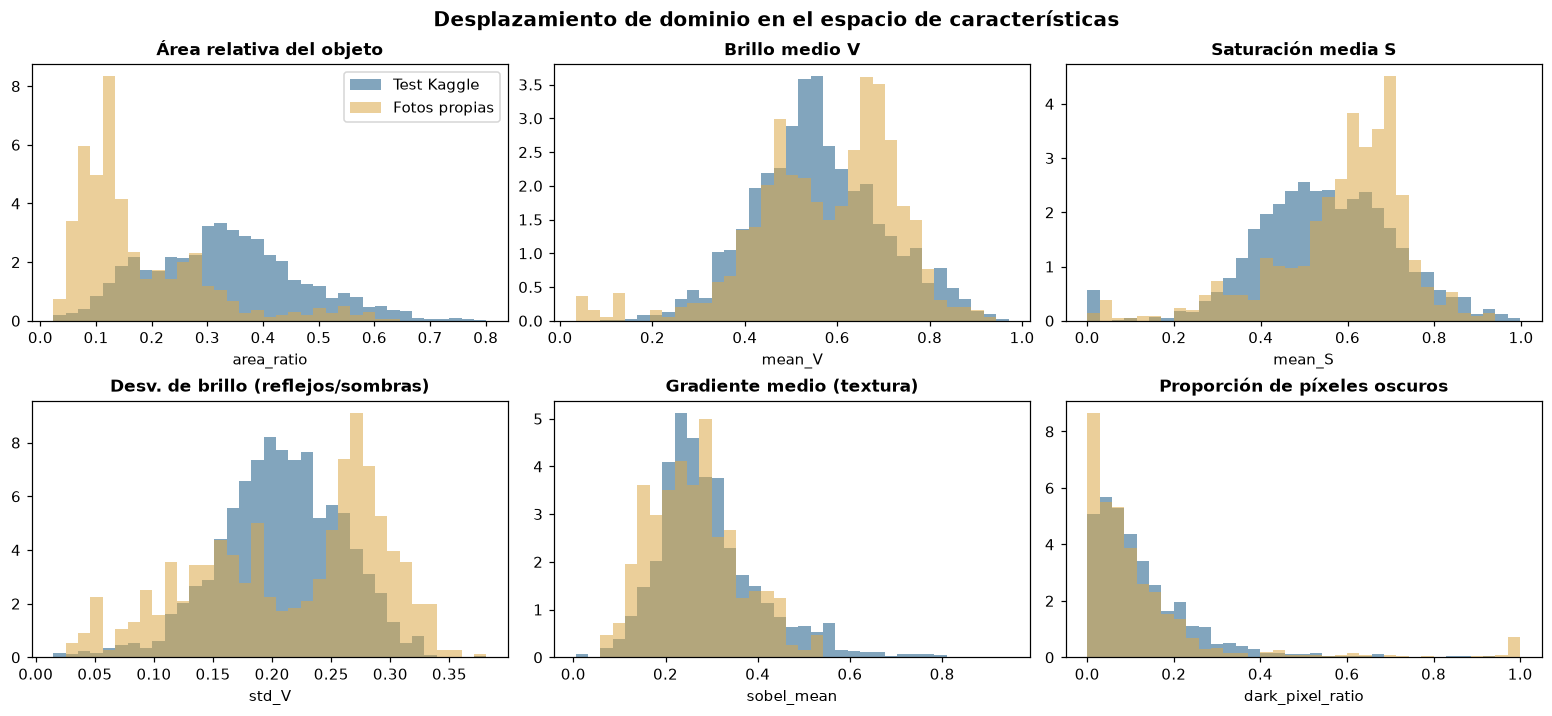

Fracción de muestras fuera del rango [p1, p99] de train, por característica (top 8):


,Test Kaggle,Fotos propias
bbox_width_norm,0.9%,13.5%
bbox_height_norm,0.9%,11.5%
std_V,2.5%,11.5%
bbox_aspect_ratio,1.9%,9.0%
std_B,2.1%,8.4%
area_ratio,1.7%,7.2%
d_norm,1.7%,7.2%
std_G,2.2%,6.6%


In [9]:
shift_features = [('area_ratio', 'Área relativa del objeto'), ('mean_V', 'Brillo medio V'),
                  ('mean_S', 'Saturación media S'), ('std_V', 'Desv. de brillo (reflejos/sombras)'),
                  ('sobel_mean', 'Gradiente medio (textura)'), ('dark_pixel_ratio', 'Proporción de píxeles oscuros')]
fig, axes = plt.subplots(2, 3, figsize=(14, 6.4), layout='constrained')
for ax, (feat, label) in zip(axes.ravel(), shift_features):
    bins = np.histogram_bin_edges(pd.concat([test_kaggle[feat], real[feat]]), bins=35)
    ax.hist(test_kaggle[feat], bins=bins, density=True, alpha=0.55, color='#1b5b88', label='Test Kaggle')
    ax.hist(real[feat], bins=bins, density=True, alpha=0.55, color='#dca848', label='Fotos propias')
    ax.set_title(label)
    ax.set_xlabel(feat)
axes[0, 0].legend()
fig.suptitle('Desplazamiento de dominio en el espacio de características', fontsize=13, fontweight='bold')
save_figure(fig, '03_domain_shift_features')
plt.show()

train_ref = df_all.loc[df_all['split'] == 'train', FEATURES]
lo, hi = train_ref.quantile(0.01), train_ref.quantile(0.99)
outside = pd.DataFrame({
    'Test Kaggle': ((test_kaggle[FEATURES] < lo) | (test_kaggle[FEATURES] > hi)).mean(),
    'Fotos propias': ((real[FEATURES] < lo) | (real[FEATURES] > hi)).mean(),
}).sort_values('Fotos propias', ascending=False)
print('Fracción de muestras fuera del rango [p1, p99] de train, por característica (top 8):')
display(outside.head(8).style.format('{:.1%}'))

## 4. Evaluación de tamaño

La talla se predice como en la fase 3: $d_{norm} = \sqrt{4A_{obj}/(\pi A_{img})}$ se compara con los terciles $q_{33}$ y $q_{66}$ de cada fruta. Como $d_{norm}$ es relativo al encuadre, depende de la **distancia de la cámara**. Por eso se reportan dos estimadores:

1. **Umbrales de Kaggle sin recalibrar** (`size_thresholds_train.json`, terciles aprendidos con train). Mide cuánto se sesga la talla cuando la distancia de captura cambia (*domain shift* de escala).
2. **Umbrales recalibrados al dominio local**: terciles de $d_{norm}$ por fruta calculados con las fotos propias, **excluyendo la muestra que se anota a mano** y las variantes aumentadas. Así la calibración no usa ninguna etiqueta de talla ni ve las fotos con las que se evalúa.

Con los umbrales locales, la distribución de tallas sale equilibrada en el conjunto de calibración **por construcción** (son terciles). La prueba real de cada estimador es la comparación con la talla anotada a mano.

El enunciado pide entre 30 y 50 fotos anotadas, así que no se anotan las 742. `src/data/prepare_custom_photos.py` marca con `size_sample = 1` una muestra estratificada de 60 fotos (12 por fruta, repartidas entre calidades). Esa muestra excluye las variantes aumentadas, los recortes de baja resolución y las fotos con varias frutas, y queda en `size_sample_sheet.png`. El grupo llena `size_label` solo en esas filas; esta celda evalúa todas las fotos que tengan `size_label`.

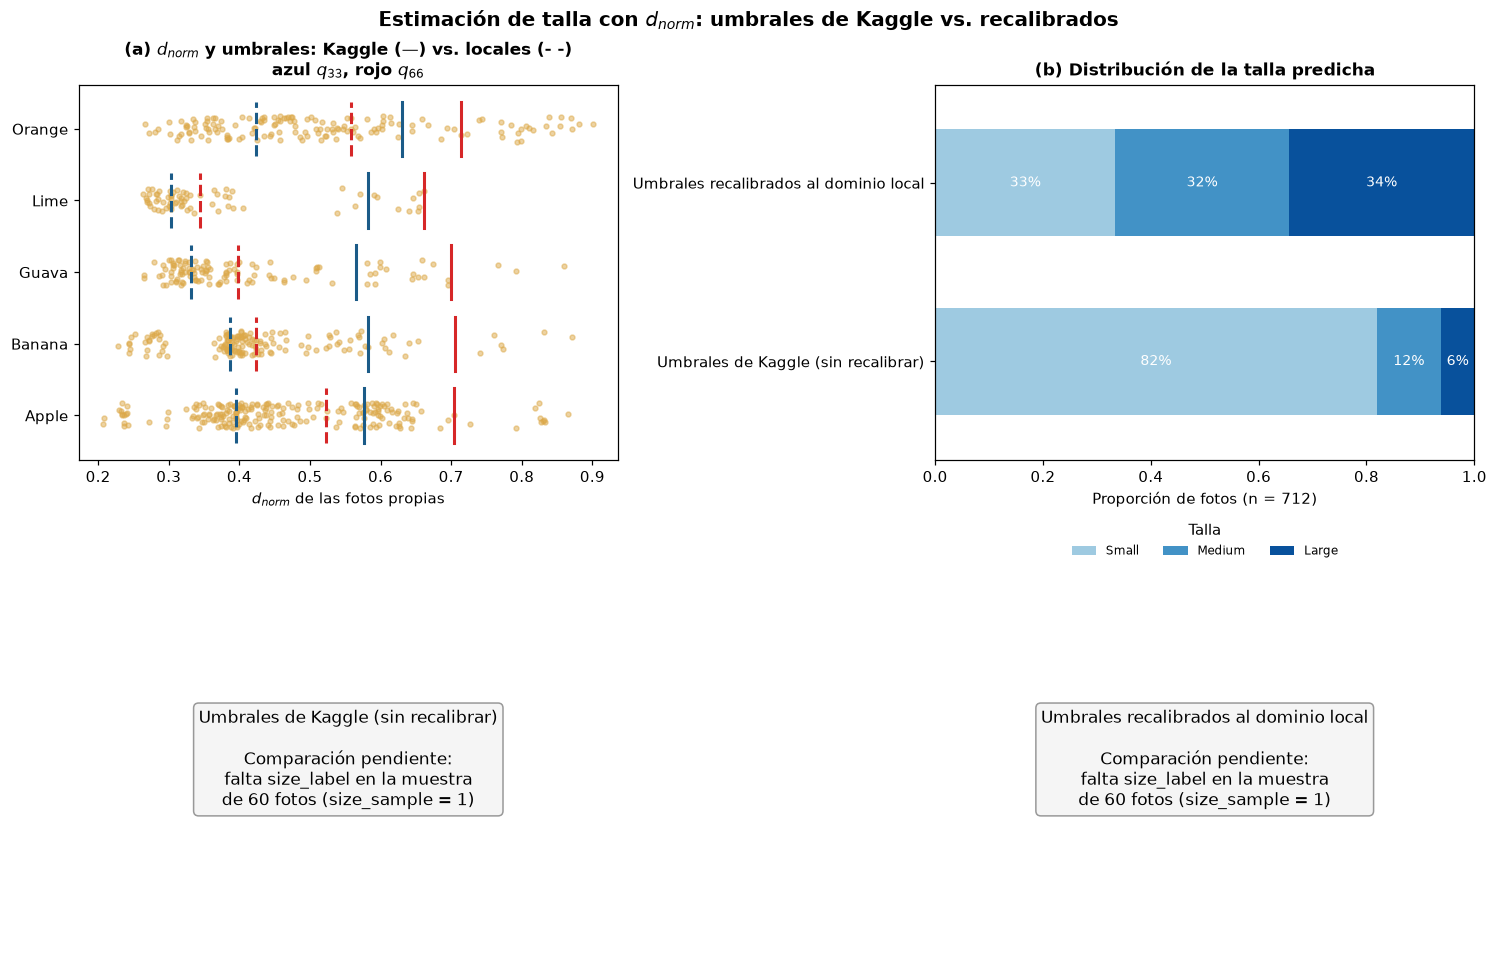

,Small,Medium,Large
Umbrales de Kaggle (sin recalibrar),81.9%,11.9%,6.2%
Umbrales recalibrados al dominio local,33.4%,32.2%,34.4%


,Apple,Banana,Guava,Lime,Orange,Pomegranate
Kaggle (train),q33 = 0.577 · q66 = 0.704,q33 = 0.582 · q66 = 0.705,q33 = 0.565 · q66 = 0.699,q33 = 0.583 · q66 = 0.662,q33 = 0.630 · q66 = 0.714,q33 = 0.568 · q66 = 0.700
Local (fotos propias),q33 = 0.395 · q66 = 0.522,q33 = 0.386 · q66 = 0.424,q33 = 0.332 · q66 = 0.398,q33 = 0.303 · q66 = 0.345,q33 = 0.423 · q66 = 0.558,—


Comparación con la talla anotada pendiente: llenar size_label en las 60 filas con size_sample = 1 de annotations_template.csv y reejecutar el cuaderno.


In [10]:
def size_category(fruit, d_norm, thresholds):
    th = thresholds[fruit]
    return 'Small' if d_norm < th['q33'] else ('Medium' if d_norm < th['q66'] else 'Large')


labeled = real['size_label'].isin(SIZE_ORDER) & ~real['augmented']
usable = real[~real['augmented']]
calibration = real[~real['augmented'] & ~real['size_sample'] & ~labeled]
LOCAL_THRESHOLDS = {
    fruit: {'q33': round(float(g['d_norm'].quantile(1 / 3)), 5), 'q66': round(float(g['d_norm'].quantile(2 / 3)), 5)}
    for fruit, g in calibration.groupby('fruit')
}
VARIANTS = {'kaggle': ('Umbrales de Kaggle (sin recalibrar)', SIZE_THRESHOLDS),
            'local': ('Umbrales recalibrados al dominio local', LOCAL_THRESHOLDS)}
for key, (_, thresholds) in VARIANTS.items():
    real[f'size_pred_{key}'] = [size_category(f, d, thresholds) for f, d in zip(real['fruit'], real['d_norm'])]

size_results = {
    'n_anotadas': int(labeled.sum()),
    'n_muestra_marcada': int(real['size_sample'].sum()),
    'n_calibracion_local': int(len(calibration)),
    'umbrales_locales': LOCAL_THRESHOLDS,
}
distribution = {}
for key, (label, _) in VARIANTS.items():
    dist = real.loc[usable.index, f'size_pred_{key}'].value_counts().reindex(SIZE_ORDER, fill_value=0)
    distribution[label] = dist / dist.sum()
    size_results[key] = {'distribucion_predicha': dist.to_dict(),
                         'proporcion_small': float(dist['Small'] / dist.sum())}
    if labeled.any():
        y_true, y_pred = real.loc[labeled, 'size_label'], real.loc[labeled, f'size_pred_{key}']
        size_results[key].update({
            'accuracy': float(accuracy_score(y_true, y_pred)),
            'f1_macro': float(f1_score(y_true, y_pred, labels=SIZE_ORDER, average='macro', zero_division=0)),
            'confusion_matrix': confusion_matrix(y_true, y_pred, labels=SIZE_ORDER).tolist(),
            'accuracy_por_fruta': real.loc[labeled].assign(ok=y_true == y_pred).groupby('fruit')['ok'].mean().to_dict(),
        })

fig, axes = plt.subplots(2, 2, figsize=(13.5, 8.6), layout='constrained')
ax = axes[0, 0]
fruits_here = [f for f in CATALOG_FRUITS if f in set(real['fruit'])]
for i, fruit in enumerate(fruits_here):
    vals = usable.loc[usable['fruit'] == fruit, 'd_norm']
    ax.scatter(vals, np.full(len(vals), i) + np.random.default_rng(i).uniform(-0.18, 0.18, len(vals)),
               s=10, alpha=0.5, color='#dca848')
    for th, style in ((SIZE_THRESHOLDS[fruit], '-'), (LOCAL_THRESHOLDS.get(fruit), '--')):
        if th:
            ax.plot([th['q33']] * 2, [i - 0.38, i + 0.38], style, color='#1b5b88', lw=2)
            ax.plot([th['q66']] * 2, [i - 0.38, i + 0.38], style, color='#d62728', lw=2)
ax.set_yticks(range(len(fruits_here)), fruits_here)
ax.set_xlabel('$d_{norm}$ de las fotos propias')
ax.set_title('(a) $d_{norm}$ y umbrales: Kaggle (—) vs. locales (- -)\nazul $q_{33}$, rojo $q_{66}$')

ax = axes[0, 1]
dist_df = pd.DataFrame(distribution).T[SIZE_ORDER]
dist_df.plot.barh(stacked=True, ax=ax, color=['#9ecae1', '#4292c6', '#08519c'], width=0.6)
for container in ax.containers:
    ax.bar_label(container, labels=[f'{w:.0%}' if w > 0.04 else '' for w in container.datavalues],
                 label_type='center', color='white', fontsize=9)
ax.set(xlim=(0, 1), xlabel=f'Proporción de fotos (n = {len(usable)})', ylabel='')
ax.set_title('(b) Distribución de la talla predicha')
ax.legend(title='Talla', loc='upper center', bbox_to_anchor=(0.5, -0.14), ncol=3, fontsize=8, frameon=False)

for ax, (key, (label, _)) in zip(axes[1], VARIANTS.items()):
    if labeled.any():
        cm = np.array(size_results[key]['confusion_matrix'])
        sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges', cbar=False,
                    xticklabels=SIZE_ORDER, yticklabels=SIZE_ORDER, ax=ax)
        ax.set(xlabel='Talla predicha', ylabel='Talla anotada')
        ax.set_title(f"({'c' if key == 'kaggle' else 'd'}) {label}\n"
                     f"exactitud = {size_results[key]['accuracy']:.2f} (n = {int(labeled.sum())})")
    else:
        ax.axis('off')
        ax.text(0.5, 0.5, f"{label}\n\nComparación pendiente:\nfalta size_label en la muestra\n"
                f"de {int(real['size_sample'].sum())} fotos (size_sample = 1)",
                ha='center', va='center', fontsize=11, transform=ax.transAxes,
                bbox={'boxstyle': 'round', 'facecolor': '#f5f5f5', 'edgecolor': '#999999'})
fig.suptitle('Estimación de talla con $d_{norm}$: umbrales de Kaggle vs. recalibrados', fontsize=13, fontweight='bold')
save_figure(fig, '04_size_evaluation')
plt.show()

display(dist_df.style.format('{:.1%}'))
display(pd.DataFrame({'Kaggle (train)': SIZE_THRESHOLDS, 'Local (fotos propias)': LOCAL_THRESHOLDS}).T
        .map(lambda t: f"q33 = {t['q33']:.3f} · q66 = {t['q66']:.3f}" if isinstance(t, dict) else '—'))
if not labeled.any():
    print(f"Comparación con la talla anotada pendiente: llenar size_label en las {int(real['size_sample'].sum())} "
          'filas con size_sample = 1 de annotations_template.csv y reejecutar el cuaderno.')

## 5. Tabla de sobreajuste: CV agrupada → Val → Test Kaggle → Test real

La CV agrupada y la validación vienen de `fase4_modelado_metricas.json`. *Val (origen distinto)* excluye los recortes de validación que comparten foto de origen con train.

,CV agrupada,Val,Val (origen distinto),Test Kaggle,Test real,Brecha Val − CV,Brecha Test Kaggle − Test real
Modelo,,,,,,,
Regresión logística,0.7911,0.8496,0.7690,0.8545,0.3439,0.0585,0.5105
SVM RBF,0.8085,0.9448,0.9121,0.9491,0.3166,0.1363,0.6325
Random Forest,0.8140,0.9574,0.9366,0.9568,0.3160,0.1435,0.6407
MLP,0.8006,0.9724,0.9630,0.9715,0.3214,0.1718,0.6501


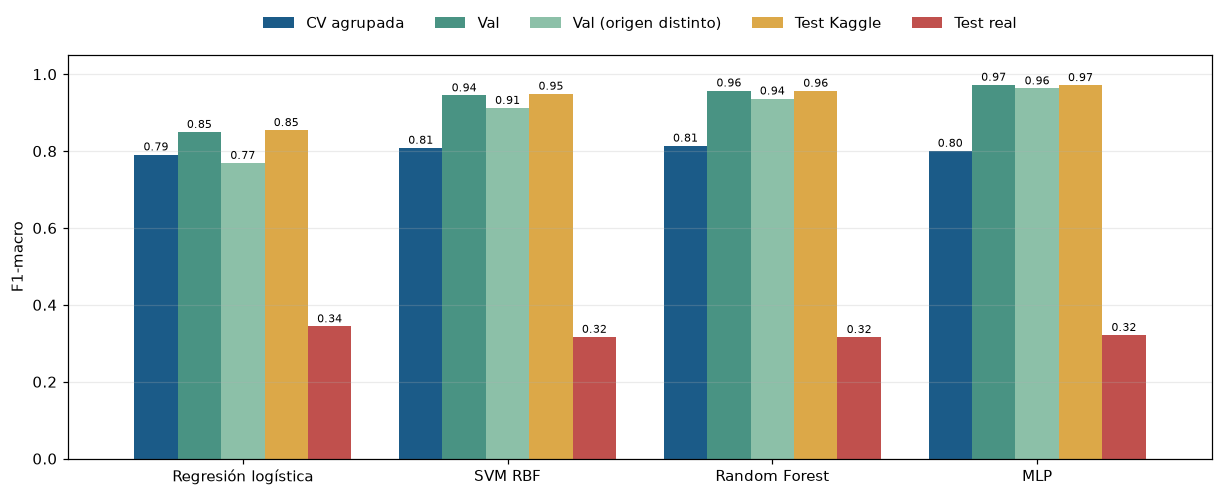

In [11]:
rows = []
for key in MODEL_NAMES:
    f4 = fase4['models'][key]
    rows.append({
        'Modelo': MODEL_NAMES[key],
        'CV agrupada': f4['cv_f1_macro_mean'],
        'Val': f4['val']['f1_macro'],
        'Val (origen distinto)': f4['val_different_source']['f1_macro'],
        'Test Kaggle': test_results[key]['f1_macro'],
        'Test real': real_results[key]['f1_macro'],
    })
overfit = pd.DataFrame(rows).set_index('Modelo')
overfit['Brecha Val − CV'] = overfit['Val'] - overfit['CV agrupada']
overfit['Brecha Test Kaggle − Test real'] = overfit['Test Kaggle'] - overfit['Test real']
display(overfit.style.format('{:.4f}').background_gradient(
    subset=['Brecha Val − CV', 'Brecha Test Kaggle − Test real'], cmap='Reds'))

stages = ['CV agrupada', 'Val', 'Val (origen distinto)', 'Test Kaggle', 'Test real']
fig, ax = plt.subplots(figsize=(11, 4.4), layout='constrained')
overfit[stages].plot.bar(ax=ax, width=0.82, color=['#1b5b88', '#499383', '#8cc0a8', '#dca848', '#c0504d'])
ax.set(ylim=(0, 1.05), ylabel='F1-macro', xlabel='')
ax.tick_params(axis='x', rotation=0)
ax.legend(ncol=5, loc='upper center', bbox_to_anchor=(0.5, 1.13), frameon=False)
ax.grid(axis='y', alpha=0.25)
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', fontsize=7, padding=1)
save_figure(fig, '05_overfitting_comparison')
plt.show()

## 6. Selección del modelo ganador

El modelo que se despliega se elige entre los dos candidatos de la fase 4 (**Random Forest** y **MLP**) con el **F1-macro en fotos reales** como criterio principal, porque es el escenario de uso de la aplicación. El F1-macro del test de Kaggle desempata.

In [12]:
candidates = ['random_forest', 'mlp']
winner = max(candidates, key=lambda k: (round(real_results[k]['f1_macro'], 3), test_results[k]['f1_macro']))
best_overall = max(MODEL_NAMES, key=lambda k: real_results[k]['f1_macro'])
display(overfit.loc[[MODEL_NAMES[k] for k in candidates], ['CV agrupada', 'Val', 'Test Kaggle', 'Test real']]
        .style.format('{:.4f}'))
print(f'Modelo ganador para la fase 6: {MODEL_NAMES[winner]} -> experiments/checkpoints/fase4_{winner}.joblib')
if best_overall not in candidates:
    print(f'Nota: el mejor F1-macro en fotos reales entre los 4 modelos es {MODEL_NAMES[best_overall]} '
          f"({real_results[best_overall]['f1_macro']:.3f}).")

per_fruit = real.assign(ok=real_preds[winner] == real['quality']).groupby('fruit').agg(
    fotos=('ok', 'size'), exactitud=('ok', 'mean'))
per_fruit['F1-macro'] = [f1_score(g['quality'], real_preds[winner][g.index], labels=CLASSES,
                                  average='macro', zero_division=0) for _, g in real.groupby('fruit')]
print(f'Desempeño de {MODEL_NAMES[winner]} en fotos reales por fruta:')
display(per_fruit.style.format({'exactitud': '{:.1%}', 'F1-macro': '{:.3f}'}))

,CV agrupada,Val,Test Kaggle,Test real
Modelo,,,,
Random Forest,0.8140,0.9574,0.9568,0.3160
MLP,0.8006,0.9724,0.9715,0.3214


Modelo ganador para la fase 6: MLP -> experiments/checkpoints/fase4_mlp.joblib
Nota: el mejor F1-macro en fotos reales entre los 4 modelos es Regresión logística (0.344).
Desempeño de MLP en fotos reales por fruta:


,fotos,exactitud,F1-macro
fruit,,,
Apple,223,51.6%,0.260
Banana,152,30.9%,0.286
Guava,117,29.1%,0.217
Lime,82,92.7%,0.627
Orange,150,61.3%,0.382


## 7. Análisis de errores

Se muestran seis fotos propias mal clasificadas por el modelo ganador, elegidas para cubrir pares (real → predicho) distintos y priorizando las de mayor confianza en la clase equivocada. Junto a cada foto se muestra la máscara de segmentación y cuatro indicadores que ayudan a explicar la causa:

* **Reflejos**: fracción de píxeles de la fruta con brillo $V > 0.92$ y saturación $S < 0.20$ (brillo especular).
* **Brillo**: $\bar V$ de la fruta (iluminación).
* **Fondo**: desviación estándar del color del borde de la imagen (fondo no uniforme o con textura).
* **Área**: `area_ratio`; valores extremos señalan una segmentación que tomó fondo o solo una parte de la fruta.

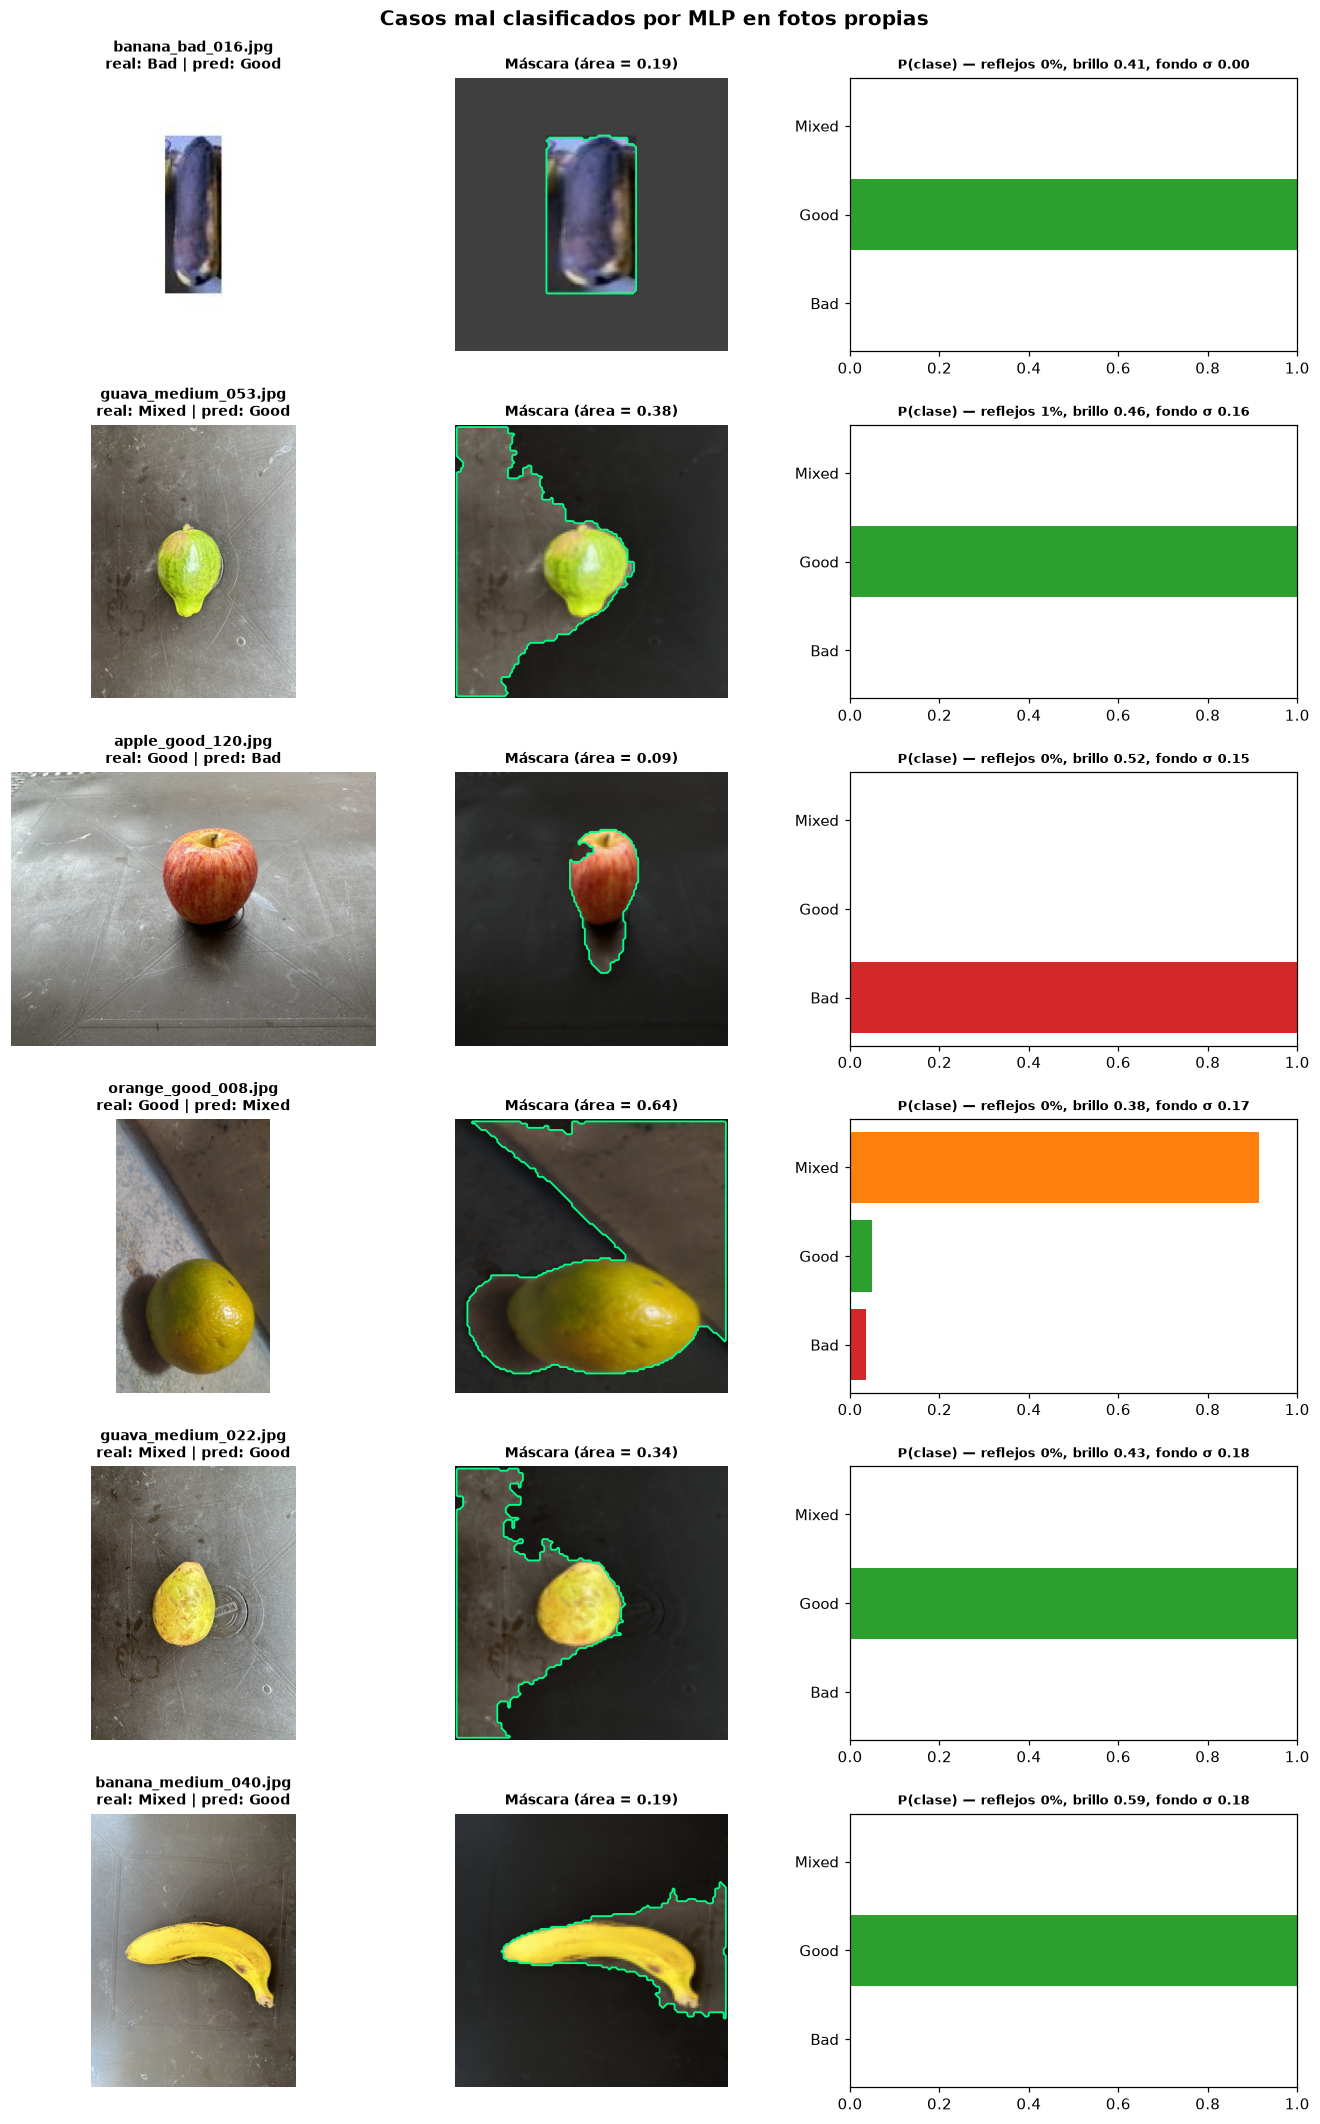

Indicadores de los casos de error (comparar con la mediana de las fotos bien clasificadas):


,caso,archivo,fruta,real,predicho,confianza,reflejos,brillo,fondo_std,area
0,1,banana_bad_016.jpg,Banana,Bad,Good,1.00,0.0%,0.41,0.000,0.19
1,2,guava_medium_053.jpg,Guava,Mixed,Good,1.00,0.6%,0.46,0.164,0.38
2,3,apple_good_120.jpg,Apple,Good,Bad,1.00,0.0%,0.52,0.152,0.09
3,4,orange_good_008.jpg,Orange,Good,Mixed,0.91,0.1%,0.38,0.168,0.64
4,5,guava_medium_022.jpg,Guava,Mixed,Good,1.00,0.0%,0.43,0.179,0.34
5,6,banana_medium_040.jpg,Banana,Mixed,Good,1.00,0.0%,0.59,0.185,0.19


,reflejos,brillo,fondo_std,area
Mediana (bien clasificadas),0.000,0.634,0.165,0.127


In [13]:
def diagnostics(path):
    with Image.open(path) as img:
        rgb = np.asarray(img.convert('RGB').resize(TARGET_SIZE, Image.Resampling.BILINEAR), dtype=np.float32) / 255.0
    mask, hsv = segment_foreground_fast(rgb)
    b = max(2, min(rgb.shape[:2]) // 25)
    border = np.concatenate([rgb[:b].reshape(-1, 3), rgb[-b:].reshape(-1, 3),
                             rgb[:, :b].reshape(-1, 3), rgb[:, -b:].reshape(-1, 3)])
    fg = hsv[mask]
    return rgb, mask, {
        'reflejos': float(((fg[:, 2] > 0.92) & (fg[:, 1] < 0.20)).mean()),
        'brillo': float(fg[:, 2].mean()),
        'fondo_std': float(border.std(axis=0).mean()),
        'area': float(mask.mean()),
    }


wrong = real.assign(pred=real_preds[winner],
                    conf=real_proba[winner].max(axis=1)).loc[lambda f: f['pred'] != f['quality']]
wrong = wrong.sort_values('conf', ascending=False)
picked, seen_pairs, seen_fruits = [], set(), set()
for idx, row in wrong.iterrows():                      # 1.º un caso por par (real, predicho) y fruta nueva
    if (row['quality'], row['pred']) not in seen_pairs and row['fruit'] not in seen_fruits:
        picked.append(idx); seen_pairs.add((row['quality'], row['pred'])); seen_fruits.add(row['fruit'])
for idx in wrong.index:                                # 2.º completar hasta 6 con frutas distintas
    if len(picked) >= 6:
        break
    if idx not in picked and wrong.loc[idx, 'fruit'] not in [wrong.loc[i, 'fruit'] for i in picked[-2:]]:
        picked.append(idx)
cases = wrong.loc[picked[:6]]

fig, axes = plt.subplots(len(cases), 3, figsize=(12, 3.2 * len(cases)),
                         gridspec_kw={'width_ratios': [1, 1, 1.15]}, layout='constrained')
case_rows = []
for r, (idx, row) in enumerate(cases.iterrows()):
    path = CUSTOM_DIR / row['filename']
    rgb, mask, diag = diagnostics(path)
    with Image.open(path) as img:
        axes[r, 0].imshow(img.convert('RGB'))
    axes[r, 0].set_title(f"{row['filename']}\nreal: {row['quality']} | pred: {row['pred']}", fontsize=9)
    overlay = rgb.copy()
    overlay[~mask] *= 0.25
    axes[r, 1].imshow(overlay)
    axes[r, 1].contour(mask, levels=[0.5], colors='#00ff88', linewidths=1.2)
    axes[r, 1].set_title(f"Máscara (área = {diag['area']:.2f})", fontsize=9)
    proba = pd.Series(real_proba[winner][idx], index=CLASSES)
    axes[r, 2].barh(CLASSES, proba, color=[QUALITY_PALETTE[c] for c in CLASSES])
    axes[r, 2].set_xlim(0, 1)
    axes[r, 2].set_title(f"P(clase) — reflejos {diag['reflejos']:.0%}, brillo {diag['brillo']:.2f}, "
                         f"fondo σ {diag['fondo_std']:.2f}", fontsize=8.5)
    for ax in axes[r, :2]:
        ax.axis('off')
    case_rows.append({'caso': r + 1, 'archivo': row['filename'], 'fruta': row['fruit'],
                      'real': row['quality'], 'predicho': row['pred'], 'confianza': float(row['conf']),
                      'origen': row['notes'].replace('origen: ', ''), **diag})
fig.suptitle(f'Casos mal clasificados por {MODEL_NAMES[winner]} en fotos propias',
             fontsize=13, fontweight='bold')
save_figure(fig, '06_error_cases_real')
plt.show()

error_cases = pd.DataFrame(case_rows)
ref_diag = pd.DataFrame([diagnostics(CUSTOM_DIR / f)[2] for f in real.loc[real_preds[winner] == real['quality'], 'filename']])
print('Indicadores de los casos de error (comparar con la mediana de las fotos bien clasificadas):')
display(error_cases.drop(columns=['origen']).style.format(
    {'confianza': '{:.2f}', 'reflejos': '{:.1%}', 'brillo': '{:.2f}', 'fondo_std': '{:.3f}', 'area': '{:.2f}'}))
display(ref_diag.median().rename('Mediana (bien clasificadas)').to_frame().T.style.format('{:.3f}'))

### 7.2 Causa de cada error (fotos propias)

| Caso | Foto | Real → Predicho | Causa probable | Evidencia |
|---|---|---|---|---|
| 1 | `banana_bad_016.jpg` | Bad → Good | **Imagen fuera de protocolo**: recorte diminuto y borroso (origen `banana_001_015.jpg`), no una foto cenital de una fruta. El ennegrecimiento no se distingue a esa resolución | Fondo σ = 0: no hay borde de fondo real que separar |
| 2 | `guava_medium_053.jpg` | Mixed → Good | **Fondo con textura y manchas**: la segmentación por saliencia toma una franja del mesón gris como fruta y diluye los defectos leves | Máscara pegada al borde izquierdo; fondo σ = 0.16 |
| 3 | `apple_good_120.jpg` | Good → Bad | **Sombra dura y fruta pequeña en el encuadre**: la máscara incluye la sombra negra y deja fuera parte de la manzana; los píxeles oscuros parecen podredumbre | Área = 0.09, frente a ≈ 0.35 en Kaggle |
| 4 | `orange_good_008.jpg` | Good → Mixed | **Fondo de dos tonos con borde diagonal**: la máscara abarca el 64 % de la imagen (fondo y sombra). Los recortes `Mixed` de Kaggle también traen mucho fondo, y el modelo asocia ese patrón con `Mixed` | Área = 0.64 |
| 5 | `guava_medium_022.jpg` | Mixed → Good | **Madurez intermedia y fondo texturizado**: las pecas son pequeñas y se pierden a 128×128; además entra parte del fondo en la máscara | Máscara pegada al borde izquierdo |
| 6 | `banana_medium_040.jpg` | Mixed → Good | **Madurez intermedia**: solo las puntas están pardas; el resto del color coincide con un banano `Good`. La máscara también se extiende al fondo derecho | Brillo 0.59, sin reflejos |

**Patrón general.** Ningún error se debe a reflejos (≤ 1 % de píxeles especulares). Dominan tres causas: (i) **fondos grises con textura o sombras** que rompen la segmentación por contraste con el borde; (ii) **encuadre más abierto** (la fruta ocupa ~10 % de la imagen frente a ~35 % en Kaggle), que deja menos píxeles útiles y desplaza `area_ratio` y `d_norm`; y (iii) **distinto significado de `Mixed`**: en Kaggle son recortes de fotos con varias frutas de calidad mezclada, no frutas de madurez intermedia. Por eso el *recall* de `Mixed` en fotos propias es ≈ 0 en los cuatro modelos.

En el test de Kaggle (7.1) los errores son casos frontera del mismo dominio: manzanas con manchas leves etiquetadas `Good`, magulladuras pequeñas en frutas `Bad` o fotos `Bad` con varias frutas.

### 7.1 Errores en el test de Kaggle

Para contrastar, los errores del ganador en el test de Kaggle (mismo dominio que el entrenamiento):

57 errores de 2352 en el test de Kaggle


Predicho,Bad,Good,Mixed
Real,,,
Bad,0,15,3
Good,15,0,7
Mixed,5,12,0


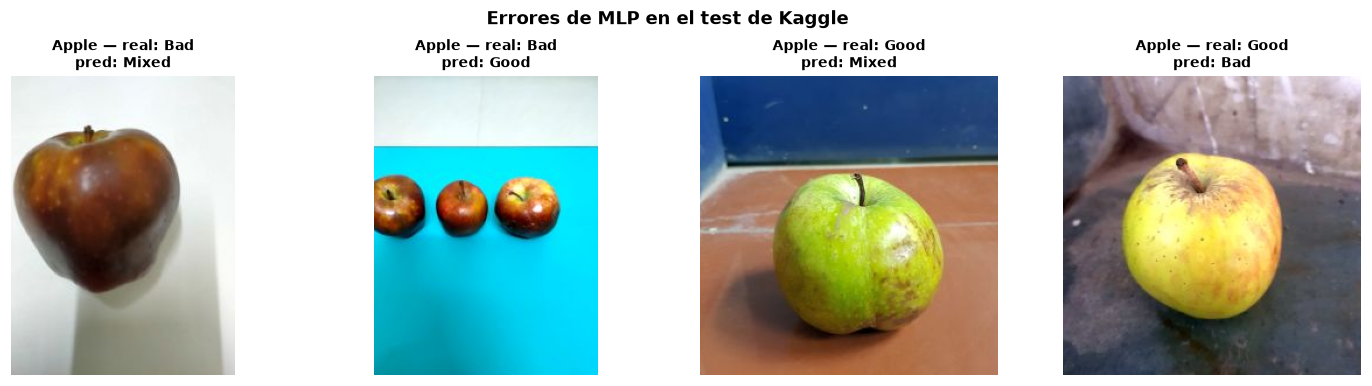

In [14]:
kaggle_wrong = test_kaggle.assign(pred=test_preds[winner]).loc[lambda f: f['pred'] != f['quality']]
print(f'{len(kaggle_wrong)} errores de {len(test_kaggle)} en el test de Kaggle')
display(pd.crosstab(kaggle_wrong['quality'], kaggle_wrong['pred'], rownames=['Real'], colnames=['Predicho']))

if KAGGLE_DIR is not None and len(kaggle_wrong):
    with tempfile.TemporaryDirectory() as tmp:
        usable = [i for i, r in kaggle_wrong.iterrows() if kaggle_image_path(r, Path(tmp)) is not None]
    show = kaggle_wrong.loc[usable].groupby(['quality', 'pred']).head(1).head(4)
    fig, axes = plt.subplots(1, len(show), figsize=(3.3 * len(show), 3.4), layout='constrained')
    axes = np.atleast_1d(axes)
    with tempfile.TemporaryDirectory() as tmp:
        for ax, (_, row) in zip(axes, show.iterrows()):
            with Image.open(kaggle_image_path(row, Path(tmp))) as img:
                ax.imshow(img.convert('RGB'))
            ax.set_title(f"{row['fruit']} — real: {row['quality']}\npred: {row['pred']}", fontsize=9)
            ax.axis('off')
    fig.suptitle(f'Errores de {MODEL_NAMES[winner]} en el test de Kaggle', fontsize=12, fontweight='bold')
    save_figure(fig, '07_error_cases_kaggle')
    plt.show()

## 8. Resumen numérico

Se guarda `experiments/results/fase5_evaluacion_metricas.json` con todas las métricas de este cuaderno.

In [15]:
summary = {
    'checkpoints_dir': 'experiments/checkpoints',
    'sklearn_version': sklearn.__version__,
    'feature_names': FEATURES,
    'class_order': CLASSES,
    'datasets': {
        'test_kaggle': {'n': int(len(test_kaggle)), 'por_clase': test_kaggle['quality'].value_counts().to_dict()},
        'test_real': {
            'n': int(len(real)),
            'por_clase': real['quality'].value_counts().to_dict(),
            'por_fruta': real['fruit'].value_counts().to_dict(),
            'variantes_aumentadas': int(real['augmented'].sum()),
            'nota': 'Medium del protocolo = Mixed del modelo; granadilla excluida por estar fuera de catálogo',
        },
        'fuera_de_catalogo': {'n': int(len(out_of_catalog)), 'frutas': out_of_catalog['fruit'].value_counts().to_dict()},
    },
    'reproducibilidad_extractor': reproducibility,
    'models': {key: {
        'name': MODEL_NAMES[key],
        'checkpoint': f'fase4_{key}.joblib',
        'cv_f1_macro': fase4['models'][key]['cv_f1_macro_mean'],
        'val_f1_macro': fase4['models'][key]['val']['f1_macro'],
        'val_different_source_f1_macro': fase4['models'][key]['val_different_source']['f1_macro'],
        'test_kaggle': test_results[key],
        'test_real': real_results[key],
        'granadilla_accuracy': granadilla.get(key, {}).get('accuracy'),
    } for key in MODEL_NAMES},
    'size_evaluation': size_results,
    'overfitting_table_f1_macro': overfit.round(6).to_dict(orient='index'),
    'winner': {
        'model': winner,
        'name': MODEL_NAMES[winner],
        'checkpoint': f'experiments/checkpoints/fase4_{winner}.joblib',
        'criterio': 'Mayor F1-macro en fotos reales entre Random Forest y MLP; desempate por F1-macro en test Kaggle',
        'test_kaggle_f1_macro': test_results[winner]['f1_macro'],
        'test_real_f1_macro': real_results[winner]['f1_macro'],
        'test_real_por_fruta': per_fruit.round(6).to_dict(orient='index'),
    },
    'error_cases_real': case_rows,
    'figures': sorted(p.name for p in FIG_DIR.iterdir()),
}
out = RESULTS_DIR / 'fase5_evaluacion_metricas.json'
out.write_text(json.dumps(summary, ensure_ascii=False, indent=2) + '\n', encoding='utf-8')
print(out.relative_to(ROOT))

experiments\results\fase5_evaluacion_metricas.json


## 9. Conclusiones de la fase 5

1. **En el dominio de Kaggle no hay sobreajuste fuerte.** El F1-macro del test coincide con el de validación (MLP 0.972 / 0.972, Random Forest 0.957 / 0.957, SVM 0.949 / 0.945, regresión logística 0.854 / 0.850). La brecha frente a la CV agrupada (≈ 0.80) se debe a que la partición aleatoria train/val/test comparte sesiones de captura: la CV agrupada es la estimación honesta dentro del dominio.
2. **En fotos propias el desempeño cae al nivel del azar** (F1-macro 0.32–0.34 con 3 clases; *recall* de `Mixed` ≈ 0). No es sobreajuste a los ejemplos de train, sino **falta de generalización a nuevas condiciones de captura**: los modelos aprendieron correlaciones del estudio de Kaggle (fondo claro, fruta grande en el encuadre, recortes `Mixed`) en vez de la calidad en sí. La normalización de las fotos a 512 px no influye: las predicciones coinciden en el 97 % de las fotos al usar los originales. El extractor también reproduce las predicciones del CSV de la fase 3 en ≈ 99 % de los casos.
3. **Modelo ganador para la fase 6: MLP (`experiments/checkpoints/fase4_mlp.joblib`).** Es el mejor en el test de Kaggle (0.972) y, entre los dos candidatos, ligeramente superior en fotos reales (0.321 frente a 0.316 del Random Forest; diferencia no significativa con n = 724). Su `predict_proba` sirve para mostrar probabilidades en la aplicación. La SVM no expone `predict_proba` porque se entrenó sin `probability=True`.
4. **Implicaciones para el despliegue.** La aplicación debe pedir las mismas condiciones de captura de Kaggle y del protocolo del grupo: fondo claro y uniforme, sin sombras duras, y fruta centrada ocupando cerca de un tercio de la imagen. También debe advertir que la clase `Mixed` es poco fiable fuera de ese dominio.
5. **Tamaño: el estimador hereda la escala de la cámara.** Con los umbrales de Kaggle sin recalibrar, el 82 % de las fotos propias (583 de 712) sale `Small`. No es un error del código: es un *domain shift* de escala. $d_{norm}$ mide el tamaño relativo al encuadre, y las fotos del grupo se tomaron más lejos que las de Kaggle, así que la fruta ocupa menos imagen. Al recalibrar los terciles con 652 fotos propias (sin usar la muestra anotada), la distribución vuelve a 33 % / 32 % / 34 %. Ese equilibrio es por construcción, y la figura 4(a) muestra que no basta: dentro de una misma fruta $d_{norm}$ forma grupos separados, como el limón en ≈ 0.3 y ≈ 0.6, que corresponden a sesiones con distancias distintas y no a frutas de distinto tamaño. Mientras la distancia no sea fija, $d_{norm}$ mezcla tamaño real y distancia. Cuál de los dos estimadores acierta más se sabrá al llenar `size_label` en las 60 fotos con `size_sample = 1` y reejecutar el cuaderno; hasta entonces la exactitud de talla queda **pendiente**. Para la aplicación conviene fijar la distancia de captura o usar un objeto de referencia de tamaño conocido.
6. **Trabajo futuro.** Reentrenar con una parte de las fotos propias (adaptación de dominio), usar una segmentación robusta a fondos texturizados (p. ej. GrabCut o un modelo de segmentación preentrenado) y redefinir `Mixed` como calidad intermedia con ejemplos propios.